# 01 · Prvi pogled: dvig in padec tehnološkega trga dela po covidu

**Vprašanje, ki ga raziskujemo:** kako sta tehnološki »boom« in nato »padec« spremenila to, *kje* se dela v IT, *katera znanja* delodajalci iščejo in *koga* doleti odpuščanje?

Tukaj samo preverimo, ali je ta zgodba sploh vidna v podatkih. Dokončnih odgovorov še ne iščemo; to pride kasneje.

**Kako brati zvezek:** vsak razdelek ima kratko razlago, graf in povzetek. Kode ti ni treba razumeti, da slediš zgodbi.

Vsi podatki so zbrani v eni datoteki (`data/processed/it_employment_master.csv`). Če je še nimaš, najprej zaženi `python build_master.py`.

**Tri poštena opozorila:**
1. Primerjamo *trende*, ne točnih števil, ker vsak vir meri malo drugačno stvar.
2. Podatki za 2026 so še nepopolni, ker leto še ni končano.
3. Podatki s Hacker Newsa in o odpuščanjih so le vzorec, ne celotna slika trga.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "build_master.py").exists())
MASTER = ROOT / "data" / "processed" / "it_employment_master.csv"
FIG = ROOT / "reports" / "figures_sl"; FIG.mkdir(parents=True, exist_ok=True)   # slovenske slike ločeno od angleških

plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 12, "axes.titleweight": "bold"})
EVENTS = {"COVID-19 (mar. 2020)": "2020-03-11", "Fed začne dvigovati obrestne mere (mar. 2022)": "2022-03-16", "ChatGPT (nov. 2022)": "2022-11-30"}

# prevodi imen, ki se pojavijo v legendah
DRZAVE = {"US": "ZDA", "GB": "Združeno kraljestvo", "DE": "Nemčija", "FR": "Francija", "ES": "Španija", "NL": "Nizozemska", "EU27_2020": "EU (27 držav)"}
REGIJE = {"US": "ZDA", "Europe": "Evropa"}
PANOGE = {"Total nonfarm": "Vsa zaposlenost (brez kmetijstva)", "Information sector": "Informacijski sektor",
          "Software publishers": "Založniki programske opreme", "Data processing, hosting & related": "Obdelava podatkov in gostovanje",
          "Computer systems design & related services": "Računalniško načrtovanje in storitve"}

m = pd.read_csv(MASTER, keep_default_na=False, dtype={"industry_code": str})
m["value"] = pd.to_numeric(m["value"], errors="coerce")
m["date"] = pd.to_datetime(m["date"])
m["year"] = m["date"].dt.year

def sel(df, **kw):
    mask = pd.Series(True, index=df.index)
    for k, v in kw.items():
        mask &= df[k].isin(v) if isinstance(v, (list, tuple, set)) else (df[k] == v)
    return df[mask]

def no_partial(df): return df[df["quality_flag"] != "partial_month"]

def events(ax, labels=True):
    lo, hi = ax.get_xlim(); y0, y1 = ax.get_ylim()
    for i, (name, d) in enumerate(EVENTS.items()):
        x = pd.Timestamp(d)
        if lo <= ax.xaxis.convert_xunits(x) <= hi:
            ax.axvline(x, color="grey", ls="--", lw=0.8)
            if labels:  # napisi so na različnih višinah, da se ne prekrivajo
                ax.text(x, y1 - (y1 - y0) * 0.09 * (i % 3), " " + name, va="top", fontsize=7, color="grey")

def save(fig, name): fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

def sl(x, nd=0, sign=False):
    """slovensko oblikovanje števil: tisočice s piko, decimalke z vejico (2.509 ; -5,6)"""
    t = f"{x:+,.{nd}f}" if sign else f"{x:,.{nd}f}"
    return t.replace(",", "X").replace(".", ",").replace("X", ".")

print(f"Imamo {sl(len(m))} vrstic podatkov iz {m.dataset.nunique()} virov.")
pregled = m.groupby("dataset").agg(vrstic=("value", "size"), od=("date", "min"), do=("date", "max"), serij=("series_id", "nunique"))
pregled

Imamo 33.788 vrstic podatkov iz 12 virov.


C:\Users\USER\AppData\Local\Temp\ipykernel_14548\3511311832.py:20: DtypeWarning: Columns (10: value) have mixed types. Specify dtype option on import or set low_memory=False.
  m = pd.read_csv(MASTER, keep_default_na=False, dtype={"industry_code": str})


,vrstic,od,do,serij
dataset,,,,
bls_ces,704,2015-01-01,2026-09-01,5
bls_qcew,1080,2015-01-01,2026-01-01,27
eurostat_isoc_sks_itspa,2904,2004-01-01,2025-01-01,148
eurostat_isoc_sks_itspe,3070,2004-01-01,2025-01-01,170
eurostat_isoc_sks_itsps,2886,2004-01-01,2025-01-01,148
eurostat_isoc_sks_itspt,1452,2004-01-01,2025-01-01,74
eurostat_lfsa_egan22d,4243,2008-01-01,2025-01-01,263
hn_whoishiring,5180,2015-01-01,2026-10-01,37
indeed_aggregate,2592,2020-02-01,2026-10-01,32


## 1 · Zaposlenost v ZDA: rast, nato umiritev (ne zlom)

Najprej poglejmo, koliko ljudi je zaposlenih v posameznih panogah. Številke so preračunane tako, da je **leto 2019 = 100**. Če je črta pri 110, je zaposlenih 10 % več kot leta 2019.

*Opomba: 2026 zajema samo januar do september.*

**Na kaj bodi pozoren:** črna črta je celotno gospodarstvo. Ali IT panoge rastejo hitreje od nje? In kje se rast ustavi ali obrne navzdol?

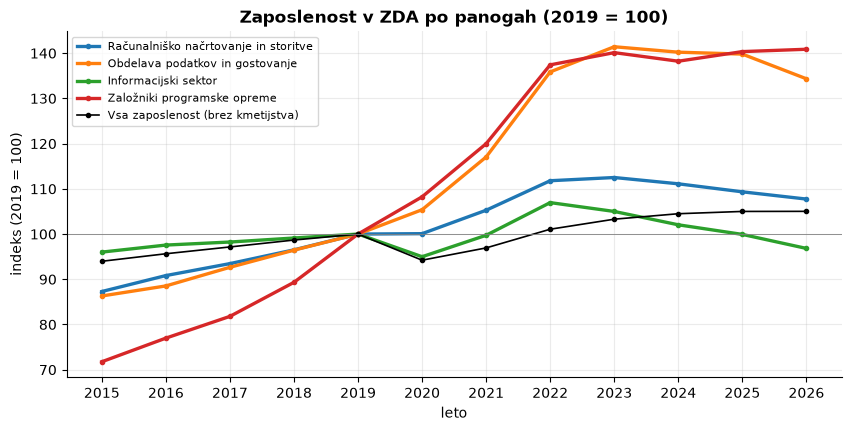

,Računalniško načrtovanje in storitve,Obdelava podatkov in gostovanje,Informacijski sektor,Založniki programske opreme,Vsa zaposlenost (brez kmetijstva)
year,,,,,
2021,105.3,117.0,99.7,120.0,96.9
2022,111.8,135.9,107.0,137.4,101.1
2023,112.5,141.4,105.0,140.1,103.3
2024,111.1,140.2,102.0,138.2,104.5
2025,109.3,139.8,99.9,140.4,105.0
2026,107.7,134.3,96.8,140.9,105.0


In [2]:
ces = sel(m, dataset="bls_ces")
letno = ces.groupby(["segment", "year"]).value.mean().unstack(0)
idx = (letno / letno.loc[2019] * 100).loc[2015:]
idx.columns = [PANOGE.get(c.split(" (")[0], c.split(" (")[0]) for c in idx.columns]
skupaj = PANOGE["Total nonfarm"]
fig, ax = plt.subplots()
for c in idx.columns:
    ax.plot(idx.index, idx[c], marker="o", ms=3, lw=2.4 if c != skupaj else 1.2,
            color="black" if c == skupaj else None, label=c)
ax.axhline(100, color="grey", lw=0.6); ax.set_title("Zaposlenost v ZDA po panogah (2019 = 100)")
ax.set_xlabel("leto"); ax.set_ylabel("indeks (2019 = 100)")
ax.legend(fontsize=8); ax.set_xticks(idx.index)
save(fig, "01_zaposlenost_zda"); plt.show()
idx.round(1).tail(6)

## 2 · IT storitve v ZDA: ista zgodba iz drugega vira

To je druga, neodvisna meritev iste stvari. Seštejemo vse vrste IT storitev (računalniško programiranje po naročilu, načrtovanje sistemov, upravljanje računalniške opreme in druge) ter pogledamo, koliko ljudi je v njih zaposlenih po četrtletjih.

**Na kaj bodi pozoren:** kdaj zaposlenost doseže vrh in koliko je zdaj pod njim?

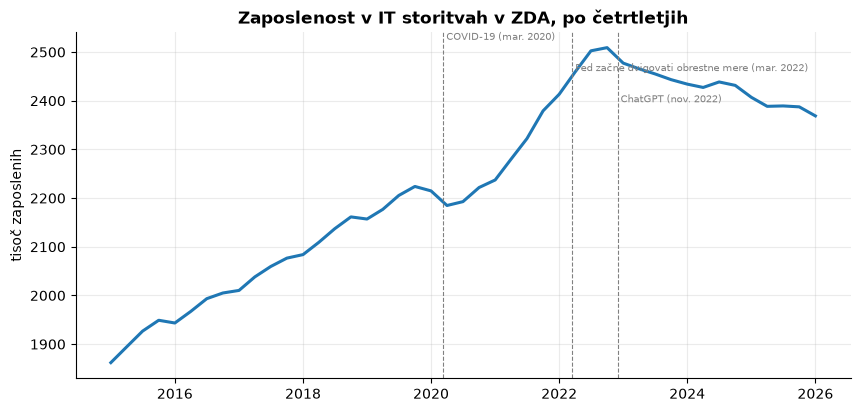

Vrh: 2.509 tisoč v 2022-Q4; zadnje četrtletje: 2.369 tisoč (-5,6 % glede na vrh)


In [3]:
q = sel(m, dataset="bls_qcew", metric="employment_level", granularity="detailed", segment_group="IT services")
qs = q.groupby("date").value.sum()
fig, ax = plt.subplots()
ax.plot(qs.index, qs.values, lw=2.2); ax.set_ylabel("tisoč zaposlenih")
ax.set_title("Zaposlenost v IT storitvah v ZDA, po četrtletjih"); events(ax)
save(fig, "02_it_storitve_zda"); plt.show()
vrh = qs.idxmax()
print(f"Vrh: {sl(qs.max())} tisoč v {vrh:%Y}-Q{(vrh.month-1)//3+1}; zadnje četrtletje: {sl(qs.iloc[-1])} tisoč ({sl((qs.iloc[-1]/qs.max()-1)*100, 1, sign=True)} % glede na vrh)")

## 3 · Povpraševanje po delavcih: najbolj očiten padec

Tukaj gledamo **objave delovnih mest** na Indeedu. Indeks je **100 = stanje 1. februarja 2020**. Če je indeks 200, je objav dvakrat več kot takrat; če je 50, jih je polovico manj.

Levo so objave za razvijalce programske opreme, desno vse objave skupaj.

**Na kaj bodi pozoren:** vrh v začetku 2022 v vseh državah ter razhajanje v zadnjem času. Objave za razvijalce v ZDA so se od sredine 2025 nekoliko opomogle, v Nemčiji, Franciji in Združenem kraljestvu pa še padajo.

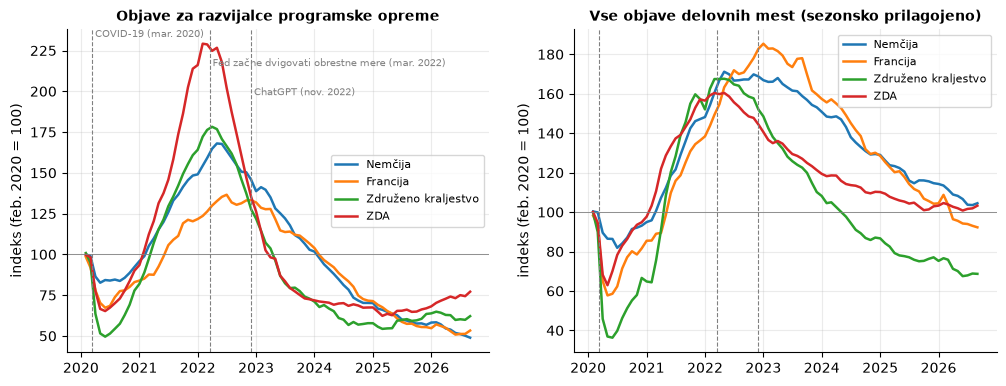

Nemčija: vrh 168 (05/2022), zdaj 49 (-71 % glede na vrh)
Francija: vrh 137 (07/2022), zdaj 53 (-61 % glede na vrh)
Združeno kraljestvo: vrh 178 (04/2022), zdaj 62 (-65 % glede na vrh)
ZDA: vrh 229 (02/2022), zdaj 77 (-66 % glede na vrh)


In [4]:
ind = no_partial(m)
razvijalci = sel(ind, dataset="indeed_it_sector", segment="Software Development", breakdown="variable=total postings")
vse = sel(ind, dataset="indeed_aggregate", breakdown="variable=total postings;seasonal=SA")
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2), sharey=False)
for ax, d, t in [(axs[0], razvijalci, "Objave za razvijalce programske opreme"), (axs[1], vse, "Vse objave delovnih mest (sezonsko prilagojeno)")]:
    for c, g in d[d.country.isin(["US", "GB", "DE", "FR"])].groupby("country"):
        ax.plot(g["date"], g["value"], label=DRZAVE.get(c, c), lw=1.8)
    ax.axhline(100, color="grey", lw=0.6); ax.set_title(t, fontsize=10); ax.legend(fontsize=8)
    ax.set_ylabel("indeks (feb. 2020 = 100)"); events(ax, labels=(ax is axs[0]))
save(fig, "03_indeed_objave"); plt.show()
for c, g in razvijalci.groupby("country"):
    g = g.set_index("date")["value"]
    print(f"{DRZAVE.get(c, c)}: vrh {sl(g.max())} ({g.idxmax():%m/%Y}), zdaj {sl(g.iloc[-1])} ({sl((g.iloc[-1]/g.max()-1)*100, 0, sign=True)} % glede na vrh)")

## 4 · Odpuščanja: koga in kdaj doleti

Število odpuščanj na tri mesece v zbirki odpuščanj, ločeno za ZDA in Evropo. Zbirko dopolnjujejo uporabniki, in vanjo pridejo samo podjetja, ki so res odpuščala. Graf torej kaže *obliko* vala, ne njegove prave velikosti.

**Na kaj bodi pozoren: dva vala.** Prvi je kratek covid šok spomladi 2020, drugi pa daljši »popravek« v letih 2022 in 2023. Samo po številu primerov sta si podobna; razliko pokaže tabela s številom odpuščenih oseb pod grafom.

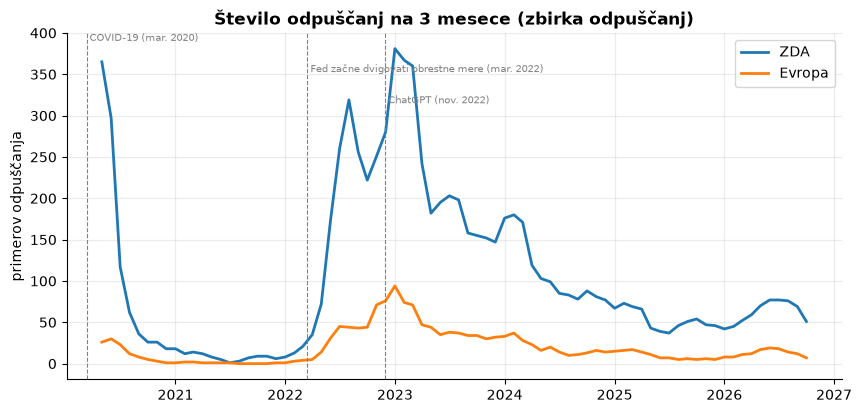

metric       primerov odpuščanja  odpuščenih oseb
leto regija                                      
2020 Evropa                 41.0           7571.0
     ZDA                   455.0          50380.0
2021 Evropa                  4.0            407.0
     ZDA                    32.0           9470.0
2022 Evropa                154.0          17096.0
     ZDA                   731.0         108546.0
2023 Evropa                172.0          48387.0
     ZDA                   860.0         178725.0
2024 Evropa                 73.0          22381.0
     ZDA                   425.0         106727.0
2025 Evropa                 35.0           6952.0
     ZDA                   205.0         102756.0
2026 Evropa                 42.0           8305.0
     ZDA                   202.0         106367.0

In [5]:
od = sel(m, dataset="layoffs_tracker", metric="layoff_events", segment_group="All industries")
ev = od.groupby(["date", "region"]).value.sum().unstack().fillna(0)
ev = ev.asfreq("MS", fill_value=0)
fig, ax = plt.subplots()
for r in ["US", "Europe"]:
    if r in ev: ax.plot(ev.index, ev[r].rolling(3).sum(), lw=2, label=REGIJE[r])
ax.set_title("Število odpuščanj na 3 mesece (zbirka odpuščanj)"); ax.set_ylabel("primerov odpuščanja"); ax.legend(); events(ax)
save(fig, "04_odpuscanja"); plt.show()
tab = sel(m, dataset="layoffs_tracker", metric=["layoff_events", "layoff_headcount"], segment_group="All industries")
tab = tab.groupby(["year", "region", "metric"]).value.sum().unstack("metric").round(0)
tab = tab.rename(columns={"layoff_events": "primerov odpuščanja", "layoff_headcount": "odpuščenih oseb"})
tab.index = tab.index.set_levels(tab.index.levels[1].map(REGIJE), level=1)
tab.index.names = ["leto", "regija"]
tab

## 5 · Evropa: v letnih podatkih ni padca

Delež »IT strokovnjakov« med vsemi zaposlenimi v Evropi (podatki Eurostata, enkrat na leto). Gre za poklic, ne za panogo: tudi računalničar, ki dela v banki, se šteje.

Združenega kraljestva ni, ker Eurostat po letu 2019 zanj nima podatkov (glej naslednji razdelek).

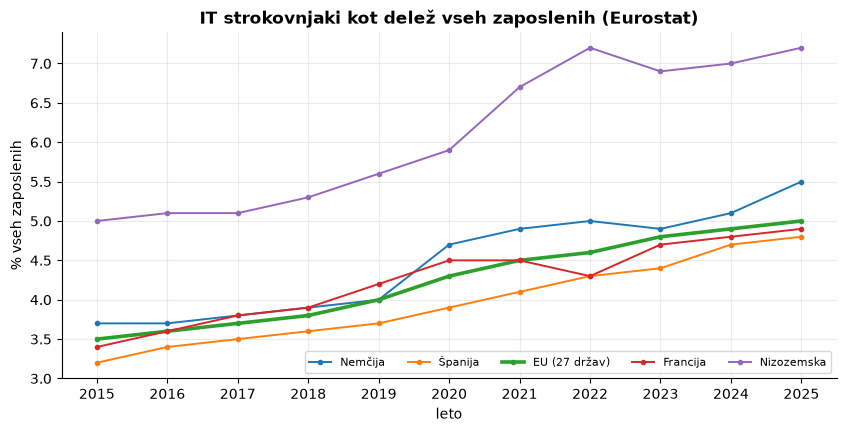

Opombe Eurostata pri teh točkah (e = ocena, b = prekinitev serije, u = manj zanesljivo): {'e': 43, 'be': 14, 'b': 9, 'd': 8, 'bd': 2}


In [6]:
e = sel(m, dataset="eurostat_isoc_sks_itspt", metric="employment_share_pct", breakdown="")
e = e[e.country.isin(["EU27_2020", "DE", "FR", "ES", "NL"])]
p = e.pivot_table(index="year", columns="country", values="value").loc[2015:]
fig, ax = plt.subplots()
for c in p.columns: ax.plot(p.index, p[c], marker="o", ms=3, lw=2.6 if c == "EU27_2020" else 1.4, label=DRZAVE.get(c, c))
ax.set_ylabel("% vseh zaposlenih"); ax.set_xlabel("leto"); ax.set_title("IT strokovnjaki kot delež vseh zaposlenih (Eurostat)")
ax.legend(fontsize=8, ncol=5); ax.set_xticks(p.index)
save(fig, "05_eurostat_it_delez"); plt.show()
print("Opombe Eurostata pri teh točkah (e = ocena, b = prekinitev serije, u = manj zanesljivo):", e[e.quality_flag != ""].quality_flag.value_counts().to_dict())

## 6 · Združeno kraljestvo in igre: edino mesto, kjer vidimo razvoj iger

Britanski statistični urad objavlja število delovnih mest do zelo podrobnih panog, zato lahko ločimo izdajatelje računalniških iger in razvijalce iger. V ZDA in EU tega ni mogoče.

Številke so preračunane tako, da je **2019 = 100**. Pozor: britanski urad števila zaokroži, zato imajo majhne panoge videz »stopnic«.

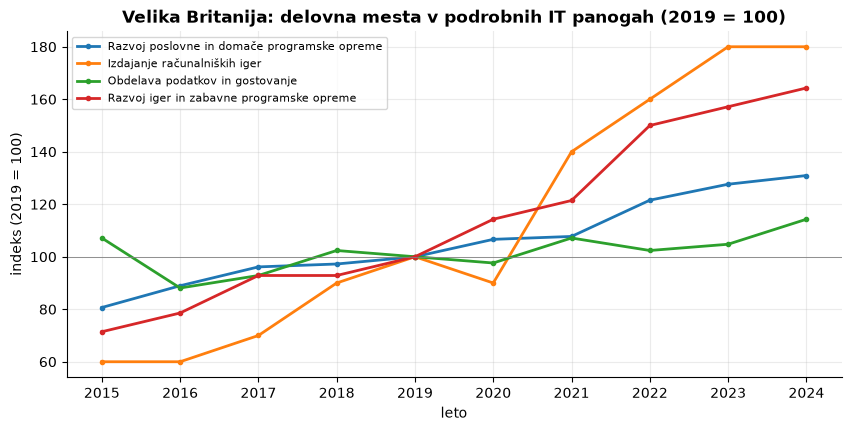

Delovna mesta v tisočih:


segment,Razvoj poslovne in domače programske opreme,Izdajanje računalniških iger,Obdelava podatkov in gostovanje,Razvoj iger in zabavne programske opreme
year,,,,
2015,146.0,1.5,45.0,10.0
2016,161.0,1.5,37.0,11.0
2017,174.0,1.8,39.0,13.0
2018,176.0,2.2,43.0,13.0
2019,181.0,2.5,42.0,14.0
2020,193.0,2.2,41.0,16.0
2021,195.0,3.5,45.0,17.0
2022,220.0,4.0,43.0,21.0
2023,231.0,4.5,44.0,22.0


In [7]:
IGRE = {"Computer games publishing": "Izdajanje računalniških iger", "Games & entertainment software development": "Razvoj iger in zabavne programske opreme",
        "Business & domestic software development": "Razvoj poslovne in domače programske opreme", "Data processing & hosting": "Obdelava podatkov in gostovanje"}
b = sel(m, dataset="ons_bres", breakdown="", industry_code=["58210", "62011", "62012", "63110"])
pb = b.pivot_table(index="year", columns="segment", values="value").rename(columns=IGRE)
ib = pb / pb.loc[2019] * 100
fig, ax = plt.subplots()
for c in ib.columns: ax.plot(ib.index, ib[c], marker="o", ms=3, lw=2, label=c)
ax.axhline(100, color="grey", lw=0.6); ax.set_title("Velika Britanija: delovna mesta v podrobnih IT panogah (2019 = 100)")
ax.set_xlabel("leto"); ax.set_ylabel("indeks (2019 = 100)"); ax.legend(fontsize=8); ax.set_xticks(ib.index)
save(fig, "06_uk_igre"); plt.show()
print("Delovna mesta v tisočih:")
pb.round(1)

## 7 · Kaj iščejo delodajalci (Hacker News »Who is hiring?«)

Vsak mesec skupnost Hacker News objavi nit, kjer podjetja oglašujejo delovna mesta. Preštejemo, kolikšen delež objav omenja posamezno stvar (npr. delo na daljavo), graf pa zgladimo s 6-mesečnim drsečim povprečjem.

**Opozorilo:** to je predvsem svet zagonskih podjetij, in računalnik išče samo ključne besede (ne razume, da »no remote« pomeni »ni dela na daljavo«). Zato rezultate jemljemo kot znamenje trenda, ne kot natančno število.

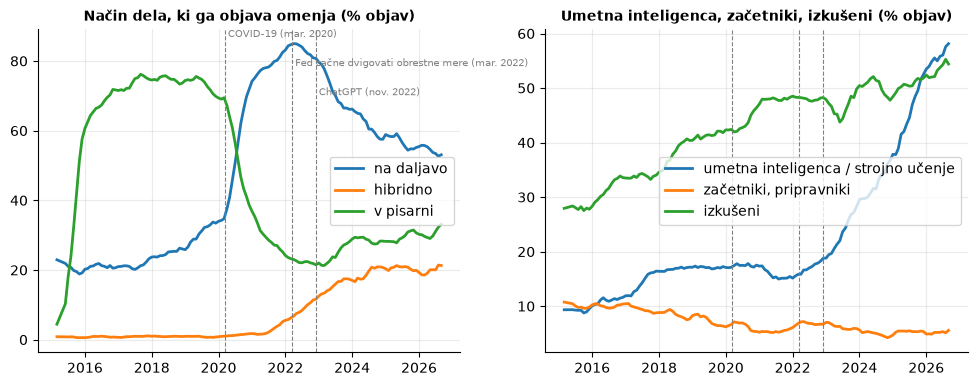

Znanja, ki so najbolj izgubila (zgoraj) in pridobila (spodaj) delež v objavah:


,2019,2025–26,sprememba (odst. točke)
segment,,,
javascript,19.5,9.4,-10.2
react,32.6,23.9,-8.7
java,10.7,3.4,-7.3
ruby,11.4,4.6,-6.8
kotlin_android,10.4,4.0,-6.3
swift_ios,9.3,3.7,-5.6
azure,1.9,2.6,0.7
terraform,4.4,5.5,1.1
gcp,4.3,5.8,1.5


In [8]:
h = no_partial(sel(m, dataset="hn_whoishiring"))
if h.empty:
    print("Podatkov s Hacker Newsa še ni: zaženi `python collect.py --sources hn`, nato `python build_master.py`.")
else:
    sh = h[h.metric == "hn_post_share"].pivot_table(index="date", columns="segment", values="value")
    ime1 = {"remote": "na daljavo", "hybrid": "hibridno", "onsite": "v pisarni"}
    ime2 = {"ai_ml": "umetna inteligenca / strojno učenje", "junior": "začetniki, pripravniki", "senior": "izkušeni"}
    fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
    for c, ime in ime1.items():
        if c in sh: axs[0].plot(sh.index, sh[c].rolling(6, min_periods=3).mean(), label=ime, lw=2)
    axs[0].set_title("Način dela, ki ga objava omenja (% objav)", fontsize=10); axs[0].legend(); events(axs[0])
    for c, ime in ime2.items():
        if c in sh: axs[1].plot(sh.index, sh[c].rolling(6, min_periods=3).mean(), label=ime, lw=2)
    axs[1].set_title("Umetna inteligenca, začetniki, izkušeni (% objav)", fontsize=10); axs[1].legend(); events(axs[1], labels=False)
    save(fig, "07_hn_nacin_dela_ai"); plt.show()
    spl = {"remote", "hybrid", "onsite", "ai_ml", "junior", "senior", "visa", "games"}
    znanja = [c for c in sh.columns if c not in spl]
    pred = sh.loc["2019":"2019"].mean().reindex(znanja).dropna(); zdaj = sh.loc["2025":"2026"].mean().reindex(znanja).dropna()
    razlika = pd.DataFrame({"2019": pred, "2025–26": zdaj}).assign(sprememba=lambda d: d["2025–26"] - d["2019"]).sort_values("sprememba")
    razlika = razlika.rename(columns={"sprememba": "sprememba (odst. točke)"})
    print("Znanja, ki so najbolj izgubila (zgoraj) in pridobila (spodaj) delež v objavah:")
    display(pd.concat([razlika.head(6), razlika.tail(6)]).round(1))

## 8 · Vse na enem grafu: ali kazalniki soglašajo, *kdaj* se je zgodilo?

Vsako črto smo prilagodili tako, da je njen **vrh = 100**. Tako ne primerjamo velikosti, temveč čas: kdaj je posamezen kazalnik dosegel vrh in kdaj je začel padati.

C:\Users\USER\AppData\Local\Temp\ipykernel_14548\3359699682.py:10: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  tl = pd.concat(deli, axis=1).loc["2020-02-01":]


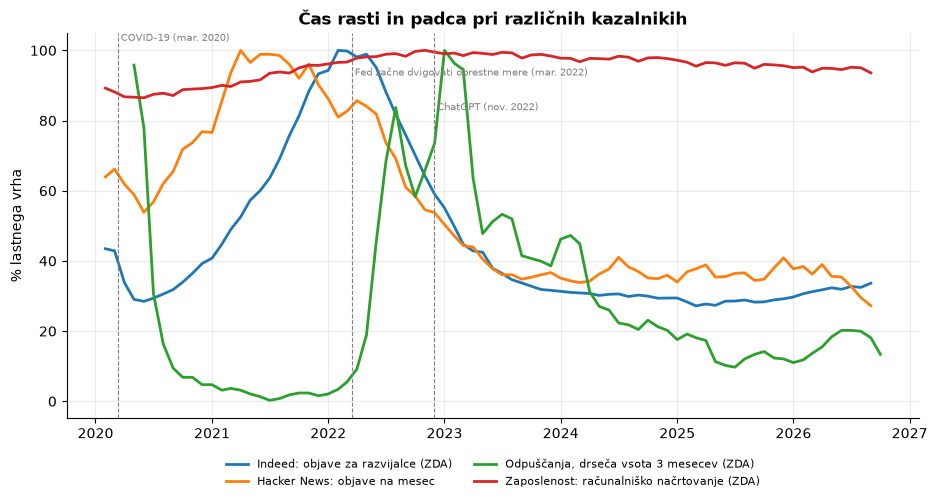

Mesec vrha po kazalniku:
Indeed: objave za razvijalce (ZDA)             02/2022
Hacker News: objave na mesec                   04/2021
Odpuščanja, drseča vsota 3 mesecev (ZDA)       01/2023
Zaposlenost: računalniško načrtovanje (ZDA)    11/2022


In [9]:
def mesecno(df, col="value"): return df.set_index("date")[col]
deli = {}
us_dev = razvijalci[razvijalci.country == "US"]
if len(us_dev): deli["Indeed: objave za razvijalce (ZDA)"] = mesecno(us_dev)
hp = h[h.metric == "hn_posts"] if not h.empty else h
if len(hp): deli["Hacker News: objave na mesec"] = mesecno(hp).rolling(3, min_periods=2).mean()
if "US" in ev: deli["Odpuščanja, drseča vsota 3 mesecev (ZDA)"] = ev["US"].rolling(3).sum()
cs = ces[ces.segment.str.startswith("Computer systems design")]
if len(cs): deli["Zaposlenost: računalniško načrtovanje (ZDA)"] = mesecno(cs)
tl = pd.concat(deli, axis=1).loc["2020-02-01":]
tl = tl / tl.max() * 100
fig, ax = plt.subplots(figsize=(11, 5))
for c in tl.columns: ax.plot(tl.index, tl[c], lw=2, label=c)
ax.set_ylabel("% lastnega vrha"); ax.set_title("Čas rasti in padca pri različnih kazalnikih")
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False); events(ax)
save(fig, "08_casovnica"); plt.show()
print("Mesec vrha po kazalniku:"); print(tl.idxmax().dt.strftime("%m/%Y").to_string())

## Kaj nam zvezek pove in česa ne

**Vidno je:**
- val povpraševanja po delavcih in njegov padec (Indeed, Hacker News),
- val odpuščanj, ki je vrhunec dosegel v letih 2022–2023,
- val dela na daljavo, ki se je deloma umaknil,
- močan porast omenjanja umetne inteligence in strojnega učenja.

**Še ni razloženo:** zakaj se je zaposlenost v ZDA le umirila in ne padla, v Evropi in Združenem kraljestvu pa še naprej raste, čeprav je povpraševanje strmo padlo.

**Česa ne moremo trditi:** vzrokov. Iz teh grafov ne moremo razbrati, ali je šlo za preveliko zaposlovanje, višje obrestne mere ali umetno inteligenco. Za to potrebujemo podrobnejše podatke (podjetja, mesta), ki jih obdelamo v nadaljevanju.